# MedPredict: Predicting Stroke 2026-27 | Kaggle Competitie
## Portfolio-opdracht 1: Voorspel herseninfarct

---
**Teamnaam:** **Y&T**  
**Competitie:** [Predicting stroke 2026-27 | Kaggle](https://www.kaggle.com/competitions/predicting-stroke-2026-27)  
**Datum:** 2026-09-10  
**Opleiding:** Applied Data Science & Artificial Intelligence  

### Teamleden & Kaggle Accounts
| # | Naam | Studentnummer | Kaggle Gebruikersnaam |
|---|------|---------------|----------------------|
| 1 | Tijn Duivenvoorden | 25059629 | [kaggle](https://www.kaggle.com/tijnd07) |
| 2 | Yorrick de Vries | 25066919 | [kaggle](https://www.kaggle.com/yorrickdevries) |



## Inhoudsopgave

1. [Exploratieve Data Analyse (EDA) & Data Voorbewerking](#1-exploratieve-data-analyse-eda--data-voorbewerking)
   - [Kolom Beschrijvingen](#11-kolom-beschrijvingen)
   - [Geschiktheid van de data voor Scikit-learn](#12-geschiktheid-van-de-data-voor-scikit-learn)
   - [Missende waardes](#13-missende-waardes)
   - [Basisstatistieken](#14-basisstatistieken)
   - [Verdelingen Numerieke Kolommen](#15-verdelingen-numerieke-kolommen)
   - [Verdeling Target Kolom (Stroke)](#16-verdeling-target-kolom-stroke)
   - [Correlaties met Target Kolom](#17-correlaties-met-target-kolom)
   - [Boxplots (Outliers)](#18-boxplots-outliers)
   - [Belangrijkste Bevindingen](#19-belangrijkste-bevindingen)
   - [Niet relevante kolommen](#110-niet-relevante-kolommen)
   - [Standaardisatie van de data](#111-standaardisatie-van-de-data)
2. [Evaluatie](#2-evaluatie)
3. [Modelleren en uitleg modellen](#3-modelleren-en-uitleg-modellen)
4. [Conclusie en advies](#4-conclusie-en-advies)
5. [Referentielijst en verantwoording generatieve AI](#5-referentielijst-en-verantwoording-generatieve-ai)

# 1. Exploratieve Data Analyse (EDA) & Data Voorbewerking

In [39]:
# =============================================================
# Data & rekenen
# =============================================================
import numpy as np
import pandas as pd

# =============================================================
# Visualisatie
# =============================================================
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns

# =============================================================
# Statistiek
# =============================================================
from scipy.stats import chi2_contingency

# =============================================================
# Preprocessing & pipelines
# =============================================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline

# =============================================================
# Class imbalance (sampling)
# =============================================================
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# =============================================================
# Modellen
# =============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# =============================================================
# Model selectie & tuning
# =============================================================
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    train_test_split,
)

# =============================================================
# Evaluatie
# =============================================================
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

In [40]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv') 

In [41]:
pd.set_option('display.max_columns', None)
train.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,False,False,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False,0


## 1.1 Kolom Beschrijvingen

**id**: Unique identifier for each individual patient record in the dataset.<br>
Geen medische betekenis. Dit is een administratief identificatienummer zonder voorspellende waarde.

**age**: Age of the patient in years (continuous numeric variable). <br>

**hypertension**: Binary flag, 1 if the patient has diagnosed chronic hypertension, 0 otherwise. <br>

**heart_disease**: Binary flag: 1 if the patient has a diagnosed heart disease, 0 otherwise. <br>

**avg_glucose_level**: Average blood glucose level measured in milligrams per deciliter (mg/dL).

**bmi**: Body Mass Index calculated as weight in kilograms divided by height in meters squared (kg/m²).

**gender_Female**: One-hot encoded columns indicating the biological gender of the patient.

**ever_married_No / ever_married_Yes**: One-hot encoded flag indicating whether the patient has ever been married.

**work_type_Private / Self_employed / Govt_job / children / Never_worked**: One-hot encoded categories representing the patient's employment sector or status.

**Residence_type_Urban / Residence_type_Rural**: One-hot encoded column indicating urban (stad) versus rural (platteland) residence.

**smoking_status_smokes / formerly_smoked / never_smoked**: One-hot encoded indicators of patient smoking history.

**stroke**: Target label: 1 if the patient experienced a stroke, 0 otherwise.

In [42]:
# Basisinformatie
print("Vorm van de dataset:")
print(train.shape)

print("\nKolommen:")
print(train.columns)

print("\nDatatypes:")
display(train.dtypes)

Vorm van de dataset:
(33550, 22)

Kolommen:
Index(['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level',
       'bmi', 'gender_Female', 'gender_Male', 'gender_Other',
       'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job',
       'work_type_Never_worked', 'work_type_Private',
       'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural',
       'Residence_type_Urban', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes', 'stroke'],
      dtype='object')

Datatypes:


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

## 1.2 Geschiktheid van de data voor Scikit-learn

Minimale vereisten:
- Geen ontbrekende waarden.
- Alle features zijn numeriek (geen tekst of string). Categorische variabelen worden daarbij een getal gemaakt
- Geen oneindige of onmogelijke waarden
- X (features) en y (target) hebben evenveel rijen en de juiste vorm
- Geen irrelevante of identificerende features (zoals id) in de dataset

## 1.3 Missende waardes

In [43]:
# Missende waarden
missende_waarden = train.isnull().sum()

missende_waarden = pd.DataFrame({
    'Kolom': missende_waarden.index,
    'Aantal missend': missende_waarden.values
})

missende_waarden['Percentage missend'] = (
    missende_waarden['Aantal missend'] / len(train) * 100
)

display(missende_waarden)


,Kolom,Aantal missend,Percentage missend
0,id,0,0.0
1,age,0,0.0
2,hypertension,0,0.0
3,heart_disease,0,0.0
4,avg_glucose_level,0,0.0
5,bmi,0,0.0
6,gender_Female,0,0.0
7,gender_Male,0,0.0
8,gender_Other,0,0.0
9,ever_married_No,0,0.0


Wij zien dat we 0 missende waarden hebben.

## 1.4 Basisstatistieken

### 1.4.1 Numerieke kolommen

In [44]:
numerieke_kolommen = [
    'age',
    'avg_glucose_level',
    'bmi'
]

statistieken = []

for kol in numerieke_kolommen:
    statistieken.append({
        'Variabele': kol,
        'Gemiddelde': train[kol].mean(),
        'Mediaan': train[kol].median(),
        'Modus': train[kol].mode()[0],
        'Minimum': train[kol].min(),
        'Maximum': train[kol].max(),
        'Standaarddeviatie': train[kol].std(),
        'Variantie': train[kol].var(),
        'Bereik': train[kol].max() - train[kol].min()
    })

stats_train = pd.DataFrame(statistieken)

display(stats_train)

,Variabele,Gemiddelde,Mediaan,Modus,Minimum,Maximum,Standaarddeviatie,Variantie,Bereik
0,age,41.815312,43.00,50.00,0.08,82.00,22.477423,505.234542,81.92
1,avg_glucose_level,103.587081,91.32,77.47,55.01,281.59,42.127396,1774.717520,226.58
2,bmi,28.601216,27.70,27.60,10.10,97.60,7.782248,60.563389,87.50


### 1.4.2 Binaire Kolommen

In [45]:
binaire_kolommen = [
    'hypertension',
    'heart_disease',
    'stroke'
]

for kol in binaire_kolommen:
    print(f"\nVerdeling van {kol}:")
    
    verdeling = train[kol].value_counts().reset_index()
    verdeling.columns = [kol, 'Aantal']
    
    verdeling['Percentage'] = (
        verdeling['Aantal'] / len(train) * 100
    )
    
    display(verdeling)


Verdeling van hypertension:


,hypertension,Aantal,Percentage
0,0,30593,91.186289
1,1,2957,8.813711



Verdeling van heart_disease:


,heart_disease,Aantal,Percentage
0,0,32106,95.695976
1,1,1444,4.304024



Verdeling van stroke:


,stroke,Aantal,Percentage
0,0,33033,98.459016
1,1,517,1.540984


### 1.4.3 Categorische Kolommen

In [46]:
categorische_kolommen = train.select_dtypes(include='bool').columns

categorie_verdeling = []

for kol in categorische_kolommen:
    categorie_verdeling.append({
        'Categorie': kol,
        'Aantal True': train[kol].sum(),
        'Percentage': train[kol].mean() * 100
    })

categorie_stats = pd.DataFrame(categorie_verdeling)

display(categorie_stats)

,Categorie,Aantal True,Percentage
0,gender_Female,20032,59.707899
1,gender_Male,13512,40.274218
2,gender_Other,6,0.017884
3,ever_married_No,12124,36.137109
4,ever_married_Yes,21426,63.862891
5,work_type_Govt_job,4156,12.387481
6,work_type_Never_worked,141,0.420268
7,work_type_Private,19279,57.463487
8,work_type_Self-employed,5126,15.278689
9,work_type_children,4848,14.450075


## 1.5 Verdelingen Numerieke Kolommen

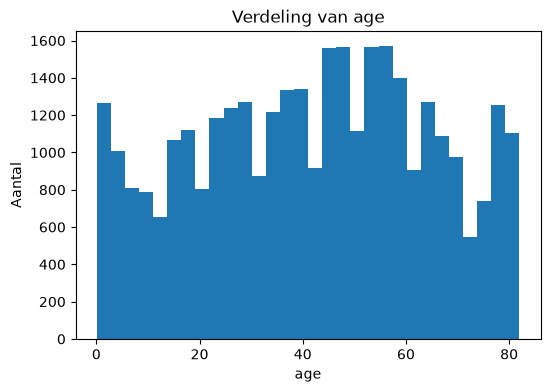

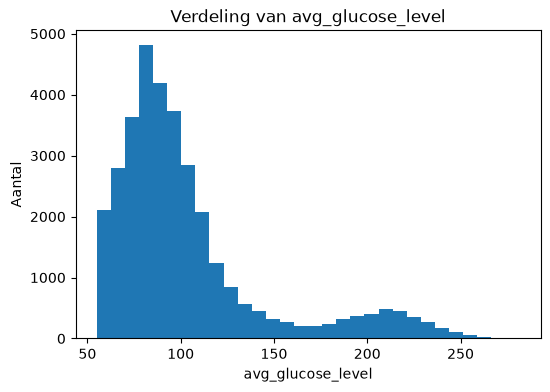

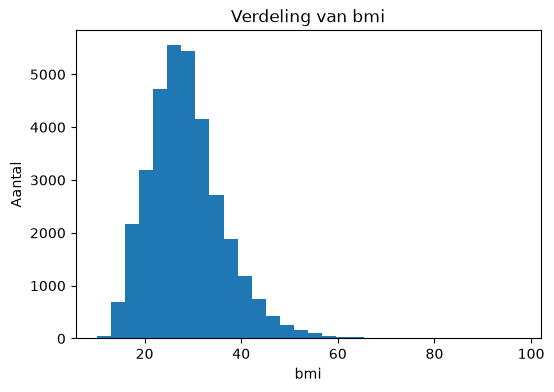

In [47]:
for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 4))
    plt.hist(train[kol].dropna(), bins=30)
    plt.title(f'Verdeling van {kol}')
    plt.xlabel(kol)
    plt.ylabel('Aantal')
    plt.show()

## 1.6 Verdeling Target Kolom (Stroke)

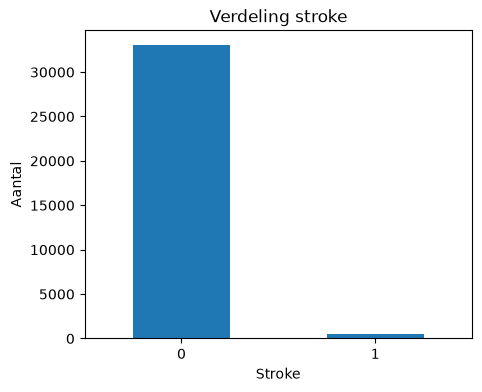

stroke
0    98.459016
1     1.540984
Name: proportion, dtype: float64


In [48]:
stroke_verdeling = train['stroke'].value_counts()

plt.figure(figsize=(5, 4))
stroke_verdeling.plot(kind='bar')

plt.title('Verdeling stroke')
plt.xlabel('Stroke')
plt.ylabel('Aantal')
plt.xticks(rotation=0)

plt.show()

print(train['stroke'].value_counts(normalize=True) * 100)

## 1.7 Correlaties met Target Kolom

In [49]:
correlaties = train.corr()['stroke'].drop('stroke')

correlaties = correlaties.reindex(
    correlaties.abs().sort_values(ascending=False).index
)

display(correlaties)

age                               0.148722
heart_disease                     0.104625
hypertension                      0.084019
avg_glucose_level                 0.076813
ever_married_Yes                  0.066403
ever_married_No                  -0.066403
work_type_Self-employed           0.061883
work_type_children               -0.050728
smoking_status_formerly smoked    0.034092
bmi                               0.020574
smoking_status_never smoked       0.009896
gender_Male                       0.008774
gender_Female                    -0.008727
smoking_status_smokes             0.008489
work_type_Never_worked           -0.008127
work_type_Private                -0.004937
work_type_Govt_job               -0.004439
Residence_type_Urban              0.002654
Residence_type_Rural             -0.002654
gender_Other                     -0.001673
id                                0.000691
Name: stroke, dtype: float64

### 1.7.1 Visualisatie

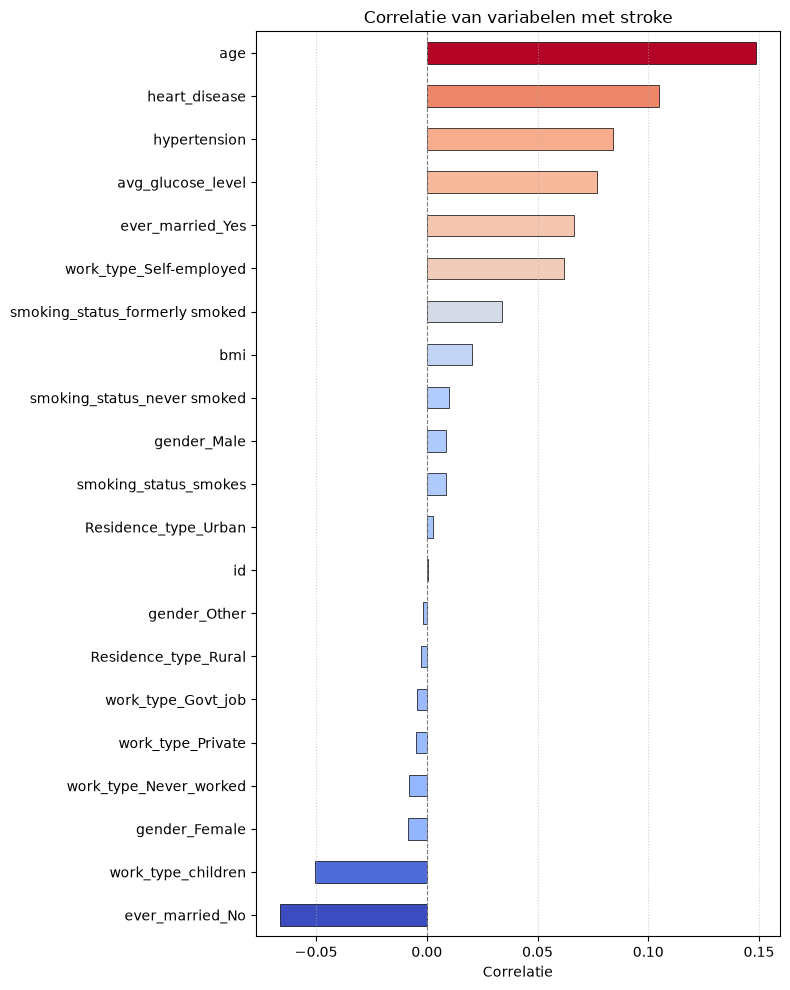

In [50]:
plt.figure(figsize=(8, 10))

data = correlaties.sort_values()

# Schaalt de waarden naar een colormap (bijv. van -1 naar 1 of min/max van de data)
norm = mcolors.Normalize(vmin=data.min(), vmax=data.max())
cmap = cm.coolwarm
kleuren = cmap(norm(data.values))

data.plot(kind='barh', color=kleuren, edgecolor='black', linewidth=0.5)

plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.title('Correlatie van variabelen met stroke')
plt.xlabel('Correlatie')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

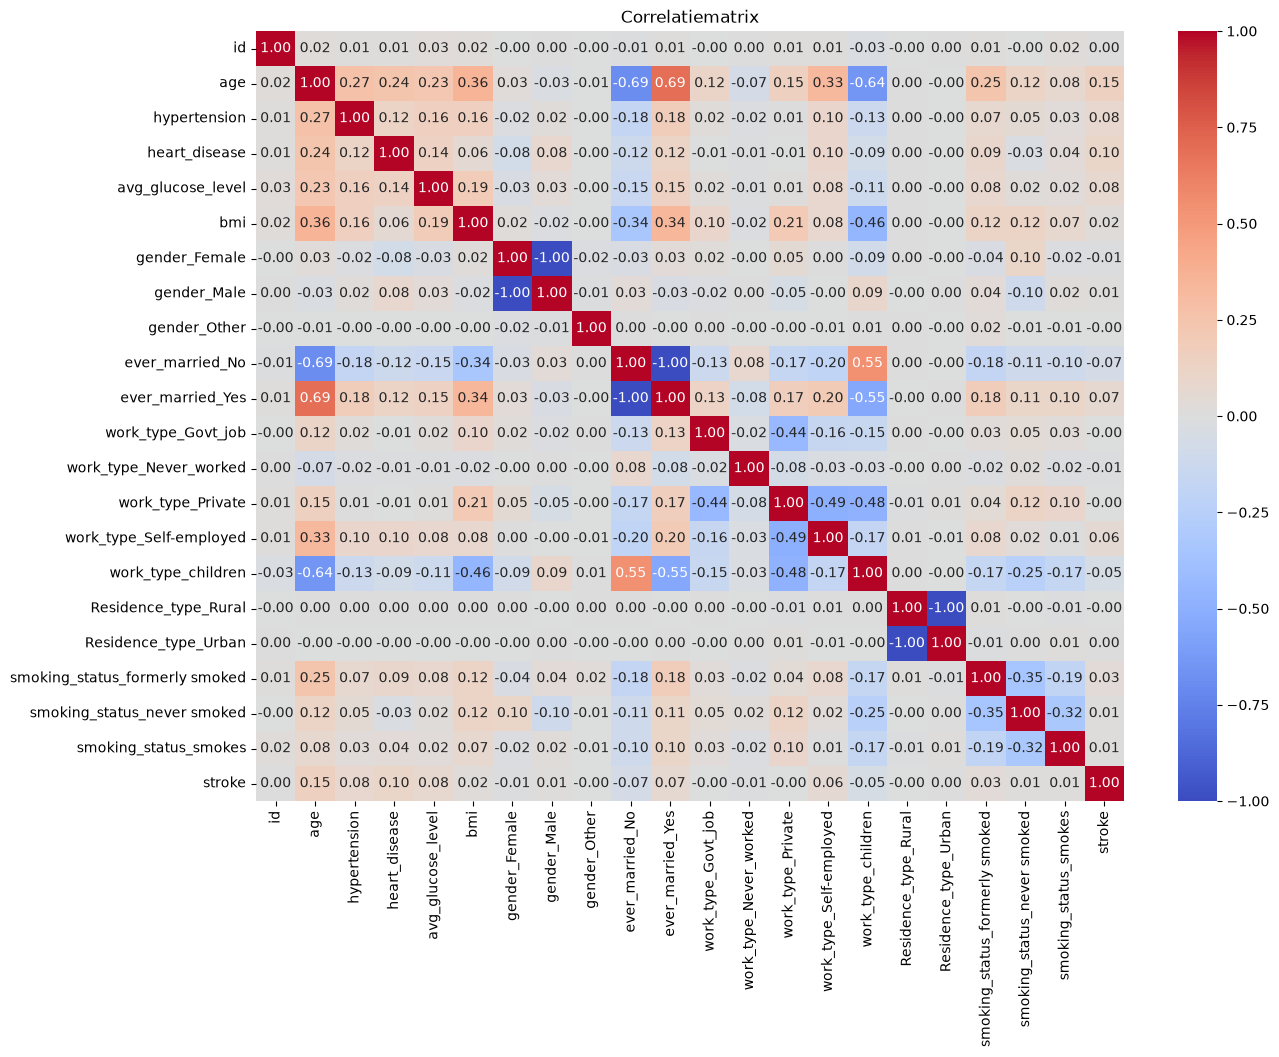

In [51]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    train.corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
)

plt.title('Correlatiematrix')
plt.show()

## 1.8 Boxplots (Outliers)

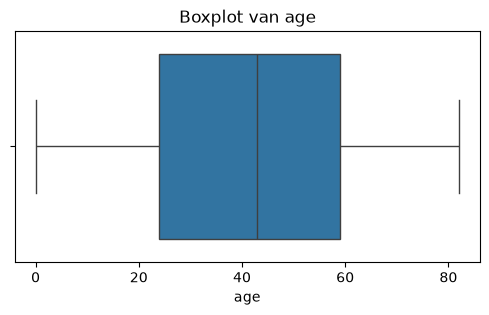

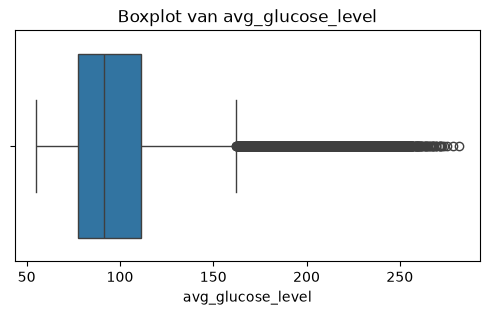

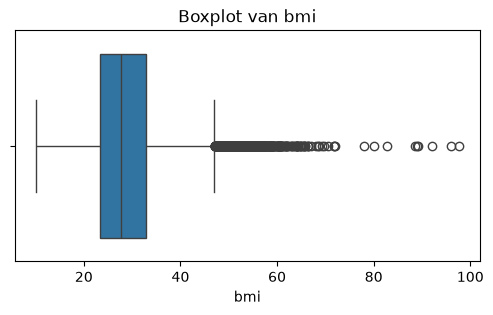

In [52]:

for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=train[kol])
    plt.title(f'Boxplot van {kol}')
    plt.show()

## 1.9 Belangrijkste Bevindingen

#### <b>Imbalanced target</b>
We zien dat van de 33.550 patienten maar slechts 517 (1,54%) een stroke heeft gehad. Dit betekent dat de dataset sterk imbalanced is. Als ons model altijd "Geen Stroke" voorspelt zou het al ongeveer 98,5% accuracy behalen zonder daadwerkelijk iets te leren. Accuracy is daarom bij deze dataset geen geschikte metric om de prestaties van het model goed te beoordelen. Dit is ook de reden waarom in de opdracht de F1-score gebruikt wordt. Later in de opdracht moeten we daarom goed kijken hoe we met deze imbalance omgaan.

#### <b>Geen missende waardes</b>
Er zijn geen missende waardes aanwezig in de dataset. Hierdoor hoeven we geen extra stappen uit te voeren om ontbrekende data te verwijderen of in te vullen.

#### <b>Age, heart_disease, avg_glucose_level en hypertension zijn de meest gecorreleerde aan stroke</b>
Van de variabelen heeft age de sterkste correlatie met stroke, met een correlatie van ongeveer 0,15. Daarnaast zien we ook een correlatie tussen stroke met: heart_disease, avg_glucose_level en hypertension. Deze correlaties zijn echter nog steeds relatief zwak. Dit laat zien dat geen van deze afzonderlijke variabelen op zichzelf een sterke relatie hebben met stroke.

#### <b>BMI en categorische waarden hebben weinig voorspellende waarde</b>
We zien dat het BMI, gender, woonplaats, werktype en rookstatus allemaal zwakke correlaties met stroke laten zien. Op basis van onze verwachtingen hadden we vooral bij rookstatus een sterke correlatie verwacht. Dat de correlatie laag is betekent niet meteen dat roken geen invloed heeft op het risico van een stroke.

#### <b>Uitschieters</b>
Uit de boxplots blijkt dat BMI en avg_glucose_level relatief veel uitschieters bevatten. Dit zijn waarschijnlijk geen foutieve waardes maar realistische metingen.

## 1.10 Niet relevante kolommen

### 1.10.1 Identificerende kolom (ID)

De ID kolom is een administratief identificatie nummer zonder voorspellende waarde. De correlatie was ook al ~0,0007.
We bewaren alleen de test-ids voor de submission op kaggle, maar halen deze eruit zodat het model niet verward wordt met het trainen en testen.

In [53]:
tests_ids = test['id']

train = train.drop(columns=['id'])
test = test.drop(columns=['id'])

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

Nieuwe vorm train: (33550, 21)
Nieuwe vorm test: (8388, 20)


### 1.10.2 Dubbele one-hot-kolommen

De categorische variabelen in de dataset zijn al one-hot-gecodeerd, dat betekend dat onze gecategoriseerde variabelen opgesplitst worden in 0/1 kolommen. De kolommen `ever_married_Yes` en `ever_married_No` tellen bijvoorbeeld samen altijd op tot 1. Dit betekend dat voor de meeste kolommen een overbodig is. Als iemand al getrouwd is `ever_married_Yes` 1 is dan weten we dat `ever_married_No` 0 is. 

Deze dubbele kolommen zijn om twee redenen een probleem:

- **KNN**: Als een categorie verandert dan veranderen er twee kolommen. Daardoor is het verschil groter dan het eigenlijk is.
- **Logistic Regression**: De kolommen hangen sterk van elkaar af. Hierdoor is het moeilijker om te bepalen welke kolom precies invloed heeft op de uitkomst.

Voor Decision Trees maakt het weinig verschil uit, maar ze verliezen hierdoor geen informatie. Daarom verwijderen we de kolommen bij alle modelen.

Per groep laten we een categorie weg. Deze categorie is de referentie. Als alle andere categorieen 0 zijn hoort de patient bij de referentiecategorie. We kiezen:

| Groep | Weggehaald | Reden |
|---|---|---|
| `ever_married` | `ever_married_No` | Als iemand getrouwd is zie je meteen 1 of 0 |
| `gender` | `gender_Female` | grootste groep, dus logische referentie |
| `work_type` | `work_type_Never_worked` | maar 141 patiënten en geen enkele stroke |
| `Residence_type` | `Residence_type_Rural` | willekeurig, beide groepen even groot |

`smoking_status` laten we hetzelfde. De kolommen tellen niet altijd op tot 1. Bij 10.320 patienten zijn alle 3 kolommen 0. 

In [54]:
smoking_cols = [col for col in train.columns if col.startswith('smoking_status_')]

# Aantal patienten waarbij alle rookkolommen 0 zijn ('Unknown')
print((train[smoking_cols].sum(axis=1) == 0).sum())

10320


In [55]:
# Kolommen per one-hot-groep
one_hot_groups = {
    'ever_married': ['ever_married_No', 'ever_married_Yes'],
    'gender': ['gender_Female', 'gender_Male', 'gender_Other'],
    'work_type': ['work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children'],
    'Residence_type': ['Residence_type_Rural', 'Residence_type_Urban'],
    'smoking_status': ['smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes'],
}

# Controle: tellen de kolommen per rij altijd op tot 1?
for group, columns in one_hot_groups.items():
    print(group, train[columns].sum(axis=1).value_counts())

ever_married 1    33550
Name: count, dtype: int64
gender 1    33550
Name: count, dtype: int64
work_type 1    33550
Name: count, dtype: int64
Residence_type 1    33550
Name: count, dtype: int64
smoking_status 1    23230
0    10320
Name: count, dtype: int64


### Conlusie

We zien dat de categorieën van `ever_married`, `gender`, `work_type` en `Residence_type` voor alle 33.550 patienten precies een waarde hebben. Hiervan kunnen we ze dus veilig verwijderen.

Bij `smoking_status` is dit anders. Bij 23.230 patienten is een van de drie categorieën ingevuld. Bij 10.320 patienten zijn alle drie de kolommen 0. 

In [56]:
# Per groep één kolom weghalen (de referentiecategorie)
redundant_cols = [
    'ever_married_No',
    'gender_Female',
    'work_type_Never_worked',
    'Residence_type_Rural',
]

train = train.drop(columns=redundant_cols)
test = test.drop(columns=redundant_cols)

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

Nieuwe vorm train: (33550, 17)
Nieuwe vorm test: (8388, 16)


### 1.10.3 Woongebied

Na 1.10.2 is van het woongebied alleen `Residence_type_Urban` over (1 = stad, 0 = platteland). Als we terug kijken naar 1.7 zi.en we dat deze variabel bijna geen correlatie heeft met stroke (0,003). We kunnen de p-waarde berekeken van deze kolom om te kijken of het toeval is of niet. 

Als we naar het resultaat hieronder kijken zien we dat de p-waarde 0,66 is. Dit laat zien dat er geen statistisch significant verband is tussen woongebied en beroerte. 

Omdat het woongebied geen duidelijk verband met `stroke` laat zien, verwijderen we deze kolom. Vooral bij KNN is dit handig, omdat een kolom zonder verband met de target wel meetelt in de afstand tussen patienten en daardoor extra ruis kan veroorzaken.

In [57]:


table = pd.crosstab(train['Residence_type_Urban'], train['stroke'])

p_value = chi2_contingency(table)[1]

print(f"p-waarde: {p_value:.2f}")

# Kolom verwijderen
train = train.drop(columns='Residence_type_Urban')
test = test.drop(columns='Residence_type_Urban')

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

p-waarde: 0.66
Nieuwe vorm train: (33550, 16)
Nieuwe vorm test: (8388, 15)


### 1.10.4 Zeldzame categorieën

Bij categorieen met maar weinig patienten kan een model moeilijk een betrouwbaar patroon leren. Daarom kijken we hoeveel patienten er per categorie zijn en hoeveel daarvan een beroerte hebben gehad. 

- **`gender_Other`**: 6 patiënten, waarvan geen enkele een beroerte heeft gehad. Als we deze kolom verwijderen worden deze patienten automatisch bij `gender_Female` ingedeeld. Daar is geen goede reden voor. Omdat er maar 6 patienten zijn in deze categorie, verwachten we weinig invloed op de modellen. Dus laten we deze kolom staan.

De overige categorieën bevatten allemaal duizenden patiënten en vormen daarom geen probleem.

In [58]:
# Stroke bij de patiënten met gender_Other
display(train.loc[train['gender_Other'] == 1, 'stroke'].value_counts())

stroke
0    6
Name: count, dtype: int64

### 1.10.5 Rookstatus

Bij `smoking_status` zijn er 10.320 patienten waarbij alle 3 kolommen 0 zijn. Dit is de categorie `unknown`. Er zijn 2 redenen waarom we deze kolommen niet weghalen, door de hoge correlatie en omdat het model "nooit gerookt" en `unknown` niet meer goed kan onderscheiden. Een aparte kolom voor `unknown` is ook niet nodig omdat dit te zien is aan 3 nullen bij de andere kolommen.

In de cel hieronder vergelijken we de rookcategorieen tegenover de leeftijd. `Unknown` heeft met 0,72% de laagste percentage een stroke. Dit komt waarschijnlijk omdat deze groep jonger is (mediane leeftijd is 20 jaar), dit zijn dus waarschijnlijk jongeren die nog nooit gerookt hebben maar ook niks hebben ingevuld. `Formerly_smoked` heeft met 2,47% het hoogste percentage, maar dit is ook de oudste groep (mediane leeftijd is 56 jaar). Leeftijd speelt waarschijnlijk een belangrijke rol tussen de rookcategorieen.

In [59]:
smoking_cols = [col for col in train.columns if col.startswith('smoking_status_')]

# Rookcategorie per patient, 'Unknown' als alle kolommen 0 zijn
smoking_status = train[smoking_cols].idxmax(axis=1).where(train[smoking_cols].sum(axis=1) == 1, 'Unknown')

# Per categorie: aantal patienten, % stroke en mediane leeftijd
display(train.groupby(smoking_status).agg(
    patienten=('stroke', 'size'),
    stroke_pct=('stroke', 'mean'),
    mediane_leeftijd=('age', 'median'),
))

,patienten,stroke_pct,mediane_leeftijd
Unknown,10320,0.007171,20.0
smoking_status_formerly smoked,5661,0.024731,56.0
smoking_status_never smoked,12602,0.016981,45.0
smoking_status_smokes,4967,0.017918,46.0


## 1.11 Standaardisatie van de data

Bij standaardisatie wordt voor iedere numerieke variabele het gemiddelde afgetrokken en wordt het resultaat gedeeld door de standaardafwijking: $z = \frac{x - \mu}{\sigma}$. De getransformeerde variabele heeft daardoor op de trainingsdata een gemiddelde van ongeveer 0 en een standaardafwijking van ongeveer 1. `StandardScaler` voert deze berekening per variabele uit. De methode is gevoelig voor uitschieters, omdat het gemiddelde en de standaardafwijking door extreme waarden worden beïnvloed ([scikit-learn developers, z.d.-a](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)).

### Waarom standaardiseren voor deze dataset?

De continue variabelen hebben duidelijk verschillende schalen. `age` loopt van 0,08 tot 82, `avg_glucose_level` van 55,01 tot 281,59 en `bmi` van 10,10 tot 97,60. Zonder standaardisatie kan een variabele met grotere numerieke verschillen zwaarder meetellen, ook als die inhoudelijk niet belangrijker is. Dit is vooral relevant voor K-Nearest Neighbors, omdat afstanden de voorspelling bepalen. De officiële scikit-learn-documentatie laat zien dat schalen bij KNN een andere neighbour structuur en beslisgrens kan opleveren. Schalen is ook relevant voor SVM en Logistic Regression; bij Logistic Regression convergeren de `sag`- en `saga`-solvers alleen betrouwbaar snel wanneer kenmerken ongeveer dezelfde schaal hebben ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html); [scikit-learn developers, z.d.-c](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)).

### Gekozen werkwijze

We standaardiseren alleen de continue variabelen `age`, `avg_glucose_level` en `bmi` met `StandardScaler`. De binaire en one-hot-gecodeerde variabelen blijven 0 of 1. Voor KNN, Logistic Regression en SVM gebruiken we de onderstaande preprocessing in een `Pipeline`. Decision Tree, Random Forest, Gradient Boosted Decision Trees en XGBoost zijn boommodellen en worden vrijwel niet beïnvloed door schaling; voor deze modellen gebruiken we daarom de oorspronkelijke waarden ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)).

De scaler wordt hier alleen als herbruikbare pipeline gedefinieerd en nog niet op de volledige dataset gefit. Tijdens cross-validation moet `fit` uitsluitend op de trainingsfold worden uitgevoerd. Een pipeline zorgt ervoor dat het gemiddelde en de standaardafwijking per trainingsfold worden geleerd en voorkomt dat informatie uit de validatie- of testdata lekt ([scikit-learn developers, z.d.-d](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)).

Omdat de boxplots uitschieters tonen, vergelijken we later tijdens cross-validation `StandardScaler` eventueel met `RobustScaler`. We kiezen `StandardScaler` als onderbouwde basisinstelling, maar bepalen op basis van validatieresultaten of een robuust alternatief werkelijk beter presteert.

In [60]:
# Prompt [nummer invullen]: Standaardisatie van de stroke-dataset

numeric_cols = [
    'age',
    'avg_glucose_level',
    'bmi',
]

# Laat zien hoever de schalen van deze variabelen uit elkaar liggen
scale_summary = (
    train[numeric_cols]
    .agg(['min', 'max', 'mean', 'std'])
    .T
    .round(2)
)

display(scale_summary)


def make_scaled_pipeline(model):
    """
    Pipeline voor de modellen die gevoelig zijn voor schaal. (KNN, LR, SVM).
    """
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'scale',
                StandardScaler(),
                numeric_cols,
            ),
        ],
        remainder='passthrough',
        verbose_feature_names_out=False,
    )

    return Pipeline(
        steps=[
            ('preprocessing', preprocessor),
            ('model', model),
        ]
    )

,min,max,mean,std
age,0.08,82.00,41.82,22.48
avg_glucose_level,55.01,281.59,103.59,42.13
bmi,10.10,97.60,28.60,7.78


De numerieke kenmerken hebben duidelijk verschillende schalen. Vooral avg_glucose_level heeft een grotere standaardafwijking dan bmi. Bij afstandsgebaseerde en schaalgevoelige modellen kan hierdoor één kenmerk onevenredig veel invloed krijgen. Daarom standaardiseren we age, avg_glucose_level en bmi voor KNN, Logistic Regression en SVM. De standaardisatie vindt binnen de modelpipeline plaats, zodat het gemiddelde en de standaardafwijking uitsluitend uit de betreffende trainingsdata worden berekend. De binaire kenmerken blijven ongewijzigd.

# 2. Evaluatie

In dit hoofdstuk bepalen we met passende classificatiemetrics hoe goed de modellen presteren.

## 2.1 Train- en validatiestrategie

*Nog uit te werken:* beschrijf de gekozen splitsing en gestratificeerde cross-validation. Leg uit hoe preprocessing, standaardisatie en technieken voor klasse-onbalans binnen iedere trainingsfold blijven om datalekken te voorkomen.

In [61]:


X = train.drop(columns="stroke")
y = train["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

print("Traindata:", X_train.shape)
print("Testdata:", X_test.shape)
print("\nStroke-verhouding traindata:")
display(y_train.value_counts(normalize=True).mul(100).round(3))
# .mul = Equivalent to ``dataframe * other``, but with support to substitute a fill_value for missing data in one of the inputs. With reverse version, rmul.
print("\nStroke-verhouding testdata:")
display(y_test.value_counts(normalize=True).mul(100).round(3))

Traindata: (26840, 15)
Testdata: (6710, 15)

Stroke-verhouding traindata:


stroke
0    98.458
1     1.542
Name: proportion, dtype: float64


Stroke-verhouding testdata:


stroke
0    98.465
1     1.535
Name: proportion, dtype: float64

Op de train data gebruiken we 5-fold stratified cross-validation. Bij iedere ronde traint het model op vier folds en evalueren we het op de overgebleven fold. Zo gebruiken we het grootste deel van de ontwikkeldata voor training en validatie, terwijl de klasseverhouding per fold ongeveer gelijk blijft. We gebruiken dezelfde folds en F1-score voor de vergelijking en tuning van alle modellen. 



## 2.2 Evaluatiemetrics en confusion matrix

Om de eerste evaluatie te maken gebruiken we Logistic Regression als baseline. Omdat de stroke class maar 1,54% van de data is, geven we de minderheidsklasse met `class_weight='balanced'` extra gewicht. Dit is een eerste aanpak tegen de onbalans, in hoofdstuk 3 vergelijken we meerdere technieken. De baseline wordt op de ontwikkeldata getraind en op de apart gehouden eindvalidatieset beoordeeld.

De confusion matrix vergelijkt de werkelijke klasse met de voorspelde klasse. Bij labels 0 en 1 gebruikt scikit-learn de volgorde `[[TN, FP], [FN, TP]]`: true negatives (TN) zijn correct herkende patiënten zonder stroke, false positives (FP) zijn patiënten zonder stroke die ten onrechte positief zijn voorspeld, false negatives (FN) zijn gemiste strokes en true positives (TP) zijn correct herkende strokes.

We rapporteren de volgende maten ([scikit-learn developers, z.d.-e](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)):

- **Accuracy** $= \frac{TP + TN}{TP + TN + FP + FN}$: het aandeel correcte voorspellingen. Door de sterke klasse-onbalans kan deze maat hoog zijn terwijl het model bijna alle strokes mist.
- **Precision** $= \frac{TP}{TP + FP}$: van de patiënten die het model als stroke aanwijst, welk aandeel had volgens de labels daadwerkelijk een stroke? Een lage precision betekent relatief veel fout-positieve signalen.
- **Recall (sensitiviteit)** $= \frac{TP}{TP + FN}$: van de patiënten met stroke, welk aandeel vindt het model? Een lage recall betekent dat het model veel strokes mist.
- **F1-score** $= 2 \cdot \frac{precision \cdot recall}{precision + recall}$: het harmonisch gemiddelde van precision en recall. F1 is laag wanneer één van beide laag is, maar houdt geen rekening met true negatives.

Dit zijn classificatiematen op basis van de beschikbare labels; ze tonen op zichzelf niet aan dat het model geschikt is voor klinisch gebruik. We interpreteren de fout-positieve en fout-negatieve voorspellingen daarom afzonderlijk.

,Metric,Score
0,Accuracy,0.753
1,Precision,0.049
2,Recall,0.825
3,F1-score,0.093


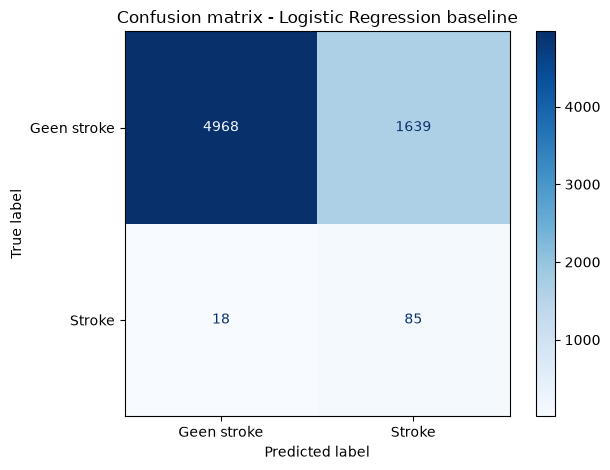

In [62]:


baseline_model = make_scaled_pipeline(
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
    )
)

baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [
        accuracy_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_baseline, zero_division=0),
        recall_score(y_test, y_pred_baseline, zero_division=0),
        f1_score(y_test, y_pred_baseline, zero_division=0),
    ],
})

display(baseline_metrics.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    display_labels=['Geen stroke', 'Stroke'],
    values_format='d',
    cmap='Blues',
)
plt.title('Confusion matrix - Logistic Regression baseline')
plt.tight_layout()
plt.show()

**Interpretatie:** 
- Er wordt 18x voorspeld geen stroke terwijl het wel een stroke is
- Er wordt 1639x stroke voorspeld terwijl het geen stroke is
- Er wordt 85x goed stroke voorspeld
- Er wordt 4968x goed geen stroke voorspeld

## 2.3 Keuze voor de F1-score

Voor deze classificatietaak wordt de F1-score gebruikt omdat de dataset sterk ongebalanceerd is: er zijn veel meer mensen zonder beroerte dan met een beroerte. Hierdoor kan accuracy een vertekend beeld geven van hoe goed het model daadwerkelijk presteert.

De F1-score combineert precision en recall. Precision geeft aan hoeveel voorspelde beroertes daadwerkelijk correct zijn, terwijl recall aangeeft hoeveel van de echte beroertes door het model worden gevonden. Beide zijn hier belangrijk. Een false positive betekent dat iemand onterecht als beroertegeval wordt voorspeld, terwijl bij een false negative een werkelijk beroertegeval wordt gemist. De F1-score zorgt ervoor dat het model een balans moet vinden tussen deze twee soorten fouten.

# 3. Modelleren en uitleg modellen

Voor ieder model passen we cross-validation en hyperparametertuning toe. Met de beste hyperparameters maken we voorspellingen voor `test.csv` en uploaden we een eigen submission naar Kaggle. Per model vergelijken we minimaal twee passende technieken voor de ongebalanceerde target en leggen we de werking daarvan uit.

## 3.1 Algemene modelaanpak

Voor alle modellen gebruiken we dezelfde 5-fold stratified cross-validation. Met `GridSearchCV` proberen we verschillende hyperparameters uit. We kiezen de instellingen met de hoogste gemiddelde F1-score.

Per model vergelijken we minimaal twee technieken om met de onbalans om te gaan. Standaardisatie en eventuele resampling zetten we in een pipeline, zodat deze stappen alleen op de trainingsdata van iedere fold worden uitgevoerd. Schalen gebruiken we bij KNN, Logistic Regression en SVM. De desiciontrees hebben dit niet nodig.

Van ieder model noteren we de beste hyperparameters en de F1-score uit cross-validation. Daarna beoordelen we het model op de apart gehouden validatieset en maken we met het gekozen model een submission voor Kaggle.

## 3.2 K-Nearest Neighbors

Standaardisatie is belangrijk, omdat kenmerken op verschillende schalen kunnen staan. Zonder het schalen kan bijvoorbeeld `avg_glucose_level` zwaarder meetellen dan `bmi`, alleen doordat de waarden groter zijn en niet omdat het belangrijker is. Door te standaardiseren krijgen alle kenmerken een vergelijkbare schaal. Hiervoor gebruiken we de preprocessing pipeline uit 1.11.

KNN heeft geen aparte regularisatieparameter. De complexiteit regelen we vooral met `n_neighbors`: weinig buren maakt het model gevoelig voor losse waarnemingen (overfitting), veel buren maakt de voorspellingen algemener (underfitting). Met `weights` tellen alle buren even zwaar mee (`uniform`) of dichtbije buren zwaarder (`distance`). Met `p` kiezen we de afstandsmaat: 1 is Manhattan, 2 is Euclidisch.

Met `GridSearchCV` vergelijken we deze instellingen, samen met RandomOverSampler en RandomUnderSampler. Voor elke combinatie bepalen we ook de beslisdrempel met de hoogste F1-score. We kiezen de combinatie met de hoogste gemiddelde F1-score uit de cross-validation.


In [63]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(KNeighborsClassifier()).named_steps["preprocessing"]

knn_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                 # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),  # 2. klassen in balans brengen
    ("model", KNeighborsClassifier()),                # 3. het KNN-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de KNN pipeline
knn_with_threshold = TunedThresholdClassifierCV(
    estimator=knn_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

# Alle combinaties van instellingen die de gridsearch gaat uitproberen
knn_param_grid = {
    "estimator__sampler": [
        RandomOverSampler(random_state=42),   # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
        RandomUnderSampler(random_state=42),  # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund 
    ],
    "estimator__model__n_neighbors": [5, 11, 21],          # aantal buren
    "estimator__model__weights": ["uniform", "distance"],  # alle buren even zwaar, of dichtbij zwaarder
    "estimator__model__p": [1, 2],                         # afstandsmaat: 1 = Manhattan, 2 = Euclidisch
}

# Probeert elke combininatie van de grid en kiest de beste op basis van de F1 score
knn_threshold_search = GridSearchCV(
    estimator=knn_with_threshold,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

knn_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_model = knn_threshold_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Beste instellingen:", knn_threshold_search.best_params_)
print("CV-F1:", round(knn_threshold_search.best_score_, 3))
print("Gekozen drempel:", round(best_model.best_threshold_, 3))
print("Validatie-F1:", round(f1_score(y_test, y_pred), 3))

KeyboardInterrupt: 

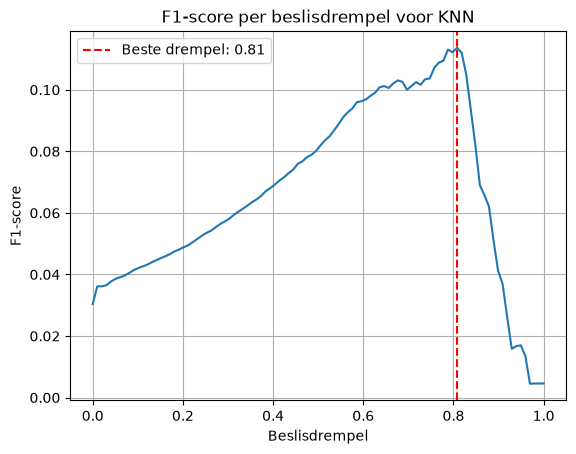

In [ ]:
results = best_model.cv_results_
best_threshold = best_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor KNN")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# from sklearn.base import clone

# # Houd de drempel uit de ontwikkeldata vast. Op alle data opnieuw tunen
# # veranderde de drempel van 0.808 naar 0.879.
# gekozen_drempel = beste_knn_met_drempel.best_threshold_
# knn_final = clone(beste_knn_met_drempel.estimator)
# knn_final.fit(X, y)

# kansen_stroke = knn_final.predict_proba(test)[:, 1]
# voorspellingen = (kansen_stroke >= gekozen_drempel).astype(int)

# submission = pd.read_csv("../data/sample_submission.csv")
# assert len(submission) == len(voorspellingen) == 8388
# assert submission['id'].equals(tests_ids.reset_index(drop=True))
# submission["stroke"] = voorspellingen
# submission.to_csv("../submission_knn_threshold_fixed.csv", index=False)
# print(f'Gebruikte drempel: {gekozen_drempel:.3f}')
# print(f'Aantal positieve voorspellingen: {voorspellingen.sum()}')

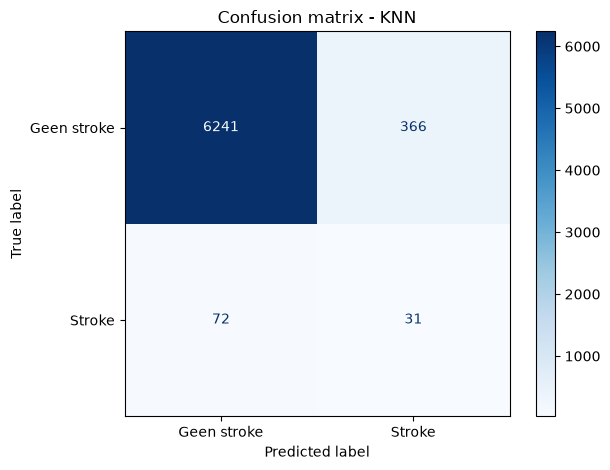

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - KNN")
plt.tight_layout()
plt.show()

### Waarom deze KNN-submission hoger scoort

- **Data:** slechts **1,54%** van de trainingsdata heeft `stroke = 1`. Daarom vergelijken we manieren om met deze onbalans om te gaan.
- **Schaling:** we standaardiseren leeftijd, glucose en BMI. Zo krijgt een kenmerk met grotere getallen niet automatisch meer invloed op de afstand tussen patiënten.
- **Onbalans:** de gridsearch koos `RandomUnderSampler`. Die haalt binnen elke trainingsfold een deel van de voorbeelden zonder stroke weg. De stroke-groep krijgt daardoor meer invloed, maar het model ziet ook minder voorbeelden zonder stroke ([imbalanced-learn developers, z.d.](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html)).
- **KNN:** de beste combinatie was **k=21**, **Manhattan-afstand** (`p=1`) en **meer gewicht voor dichtbijzijnde buren** (`weights='distance'`). Dit was de combinatie met de hoogste gemiddelde F1-score in de gridsearch ([scikit-learn developers, z.d.-f](https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)).
- **Drempel:** cross-validation op de ontwikkeldata koos **0,808**. Vanaf die score voorspellen we stroke. Op alle trainingsdata opnieuw afstemmen gaf **0,879** ([scikit-learn developers, z.d.-g](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html)).
- **Effect:** met drempel 0,879 waren er **210** positieve Kaggle-voorspellingen; met de vastgehouden drempel 0,808 waren dat **534**. Meer positieve voorspellingen kunnen meer echte strokes opleveren, maar ook meer fout-positieven.
- **F1-scores:** **0,126** in cross-validation, **0,124** op de validatieset en **0,13071** op Kaggle. De submission met drempel 0,879 scoorde **0,04968**. De eerste KNN-submission scoorde **0,09785**, maar had ook andere modelinstellingen.
- **Conclusie:** de score is boven de vereiste **0,1**. Omdat de Kaggle-labels verborgen zijn, kunnen we niet precies zeggen welke keuze hoeveel heeft geholpen. Dit resultaat betekent ook niet dat het model al geschikt is voor gebruik in de zorg.

## 3.3 Logistic Regression

### 3.3.1 Werking

Logistic regression wordt gebruikt om te voorspellen welke klasse bij een datapunt hoort. Bij binaire classificatie zijn er twee mogelijke klassen, bijvoorbeeld 0 (no stroke) en 1 (stroke).

Het model krijgt meerdere inputs, bijvoorbeeld leeftijd, bmi en gemiddelde glucoselevel. Daarna berekent het model de gewogen som van de variabelen. Met de volgende formule:

$$
z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

De uitkomst hiervan wordt door een sigmoidfunctie gehaald. Deze zet de waarde om naar een kans tussen 0 en 1.

$$
\boxed{\hat{y} = \sigma(z) = \frac{1}{1+e^{-z}}}
$$

Daarna wordt met hulp van een decision threshold bepaald welke klasse het wordt. Meestal is 0,5 de grens: kans ≥ 0,5 → klasse 1, kans < 0,5 → klasse 0.

Met hulp van loss functies kunnen we meten hoe goed ons model werkt. De formule van de loss functie is:

$$
\boxed{
L(y,\hat{y}) =
-\left[
y\log(\hat{y})
+
(1-y)\log(1-\hat{y})
\right]
}
$$

Hierbij is $y$ de werkelijke klasse, $\hat{y}$ ons voorspelde kans en $L$ de loss/error van de voorspelling. Voor de hele dataset nemen we het gemiddelde met de som ($\sum$) over alle datapunten.
De loss kan aangeven hoe goed de voorspelde kans overeenkomt met de daadwerkelijke klasse. Als de klasse 1 is en wij voorspelde 0,9 dan is dat een lage loss en dus een goede voorspelling. Maar als het model 0,2 voorspelt, dan is de loss hoger en is het dus een slechte voorspelling.

Het doel is om tijdens het trainen de parameters zo aan te passen dat de gemiddelde loss zo klein mogelijk wordt. Met gradient descent past het model de gewichten aan om de loss zo steeds kleiner te maken. De formule daarvoor is:

$$
w_{\text{nieuw}}
=
w_{\text{oud}}
-
\alpha
\frac{\partial J}{\partial w}
$$

Hier is $\alpha$ de learning rate (hoe grote stappen het model neemt). De gradient geeft aan in welke richting de loss verandert. Als de gradient positief is dan gaat die het gewicht verlagen en als de gradient negatief is dan verhoogt die het gewicht. Zo probeert het model stap voor stap de loss zo klein mogelijk te maken.


### 3.3.2 Rekenvoorbeeld


---


### 3.3.3 Regularisatie 

Bij logistic regression kun je regularisatie gebruiken om overfitting te voorkomen. Hier wordt een extra strafterm aan de loss functie toegevoegd. Grote gewichten worden daardoor bestraft.
Er zijn 2 soorten

<strong>L1-regularisatie Lasso</strong>

Bij L1 wordt de absolute waarde van de gewichten opgeteld bij de loss:

$$
J_{\text{L1}}
=
J_{\text{loss}}
+
\lambda
\sum_{j=1}^{n}|w_j|
$$

Dit straft grote gewichten en kan sommige gewichten helemaal naar 0 brengen. Hierdoor worden bepaalde variabelen niet meer gebruikt door het model. Kort gezegd kan L1 dus variabelen uit het model verwijderen.

<strong>L2-regularisatie</strong>

Bij L2 worden de gekwadrateerde gewichten gebruikt:

$$
J_{\text{L2}}
=
J_{\text{loss}}
+
\lambda
\sum_{j=1}^{n}w_j^2
$$

Dit bestraft grote gewichten sterker, maakt gewichten kleiner maar niet precies 0. Dus kortgezegd maakt L2 variabelen kleiner maar houdt wel alle variabelen.

Regularisatie wordt gebruikt om overfitting te verminderen. Bij overfitting leert het model de trainingsdata te goed. Hierdoor kan het model op de trainingsdata goed presteren, maar op nieuwe data slechter. Zonder regularisatie probeert LR de loss zo klein mogelijk te maken. Hierdoor kunnen sommige gewichten erg groot worden wanneer het model zich sterk aanpast aan de trainingsdata. Regularisatie voegt daarom een strafterm toe aan de loss functie. Het model probeert dan niet alleen de voorspellingen zo goed mogelijk te maken, maar wordt ook gestraft voor grote gewichten. 

Het belangrijkste doel is dus niet om de trainingsdata zo goed mogelijk te onthouden, maar om een model te krijgen dat goed generaliseert naar nieuwe, ongeziene data.




<small>Formules gemaakt door ChatGPT https://chatgpt.com/share/6ac26f99-0190-83eb-b42b-13209d314d0c</small>

In [ ]:
# Gebruikt de schaalstap uit onze scaled pipeline 
preprocessing = make_scaled_pipeline(LogisticRegression()).named_steps["preprocessing"]

lr_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                   # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),    # 2. klassen in balans brengen
    ("model", LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    )),                                                 # 3. het Logistic Regression-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de decision threshold met de hoogste F1-score
lr_with_threshold = TunedThresholdClassifierCV(
    estimator=lr_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

# Alle combinaties van instellingen die GridSearch gaat testen
lr_param_grid = {
    "estimator__sampler": [
        RandomOverSampler(random_state=42),     # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
        RandomUnderSampler(random_state=42),    # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund 
    ],

    "estimator__model__l1_ratio": [
        0, # Ridge (L2)
        1, # Lasso (L1)
    ],

    "estimator__model__C": [ 
        0.01,
        0.1,
        1,
        10,
        100,
    ], # Regularization strength
}

# Probeert elke combininatie van de grid en kiest de beste op basis van de F1 score
lr_threshold_search = GridSearchCV(
    estimator=lr_with_threshold,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

lr_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_lr_model = lr_threshold_search.best_estimator_

y_pred_lr = best_lr_model.predict(X_test)

print("Beste instellingen:", lr_threshold_search.best_params_)
print("CV-F1:", round(lr_threshold_search.best_score_, 3))
print("Gekozen drempel:", round(best_lr_model.best_threshold_, 3))
print("Test-F1:", round(f1_score(y_test, y_pred_lr), 3))

Beste instellingen: {'estimator__model__C': 0.01, 'estimator__model__l1_ratio': 1, 'estimator__sampler': RandomOverSampler(random_state=42)}
CV-F1: 0.15
Gekozen drempel: 0.827
Test-F1: 0.109


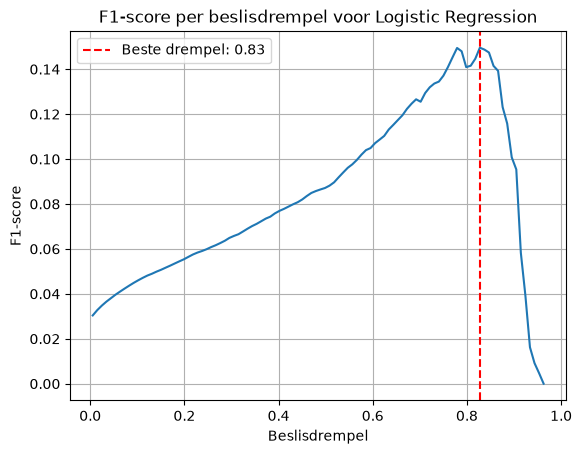

In [ ]:
results = best_lr_model.cv_results_
best_threshold = best_lr_model.best_threshold_

plt.plot(results["thresholds"], results["scores"])
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste drempel: {round(best_threshold, 2)}")

plt.xlabel("Beslisdrempel")
plt.ylabel("F1-score")
plt.title("F1-score per beslisdrempel voor Logistic Regression")
plt.legend()
plt.grid()
plt.show()

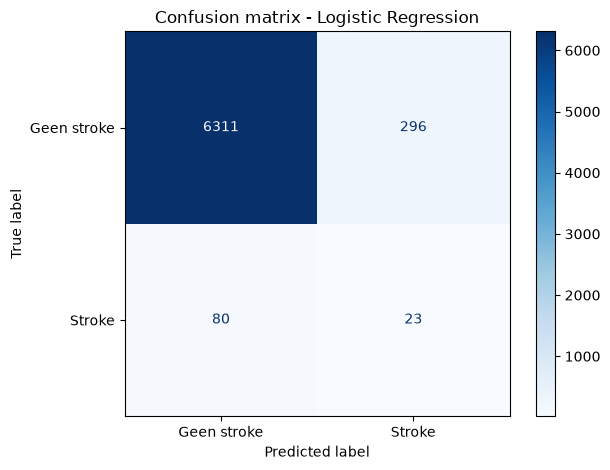

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["Geen stroke", "Stroke"],
    cmap="Blues",
)

plt.title("Confusion matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [ ]:
# from sklearn.base import clone

# # Houd de drempel uit de ontwikkeldata vast.
# # We tunen de drempel NIET opnieuw op X en y.
# gekozen_drempel = lr_threshold_search.best_estimator_.best_threshold_

# # Clone alleen het beste Logistic Regression model (zonder de threshold-tuning)
# lr_final = clone(lr_threshold_search.best_estimator_.estimator)

# # Train het model opnieuw op alle beschikbare ontwikkeldata
# lr_final.fit(X, y)

# # Voorspel de kans op stroke voor de testdata
# kansen_stroke = lr_final.predict_proba(test)[:, 1]

# # Gebruik de eerder gekozen threshold
# voorspellingen = (kansen_stroke >= gekozen_drempel).astype(int)

# # Submission inladen
# submission = pd.read_csv("../data/sample_submission.csv")

# # Controleren of alles overeenkomt
# assert len(submission) == len(voorspellingen) == 8388
# assert submission["id"].equals(tests_ids.reset_index(drop=True))

# # Voorspellingen toevoegen
# submission["stroke"] = voorspellingen

# # Submission opslaan
# submission.to_csv("../submission_lr_threshold_fixed.csv", index=False)

# print(f"Gebruikte drempel: {gekozen_drempel:.3f}")
# print(f"Aantal positieve voorspellingen: {voorspellingen.sum()}")

Gebruikte drempel: 0.827
Aantal positieve voorspellingen: 440


## 3.4 SVM

*Nog uit te werken:* beschrijf de werking met relevante formules en een rekenvoorbeeld op een klein deel van de dataset. Leg kernel en kernel trick, de loss-functie en regularisatie uit en bepaal de beste hyperparameters.

### 3.4.1 Werking

Een support vector machine, kort voor SVM, wordt gebruikt om datapunten van verschillende klassen van elkaar te scheiden. Bij binaire classificatie probeert SVM een scheidingsvlak te vinden waarmee je de twee klassen zo goed mogelijk van elkaar worden gescheiden. Hierbij gebruikt hij dezelfde formule als bij LR.

$$
f(x) = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

Maar SVM probeert niet zomaar een scheidingslijn te vinden. Het doel is om de grootst mogelijke marge tussen twee klassen te vinden. De marge wordt hierbij bepaald door de lengte van de gewichtenvector
$$
\boxed{\text{marge} = \frac{2}{\lVert w \rVert}}
$$

$$
\lVert w \rVert = \sqrt{w_1^2 + w_2^2 + \dots + w_n^2}
$$

Een kleinere $\lVert w \rVert$ betekent dus een grotere marge. De datapunten die het dichts bij het scheidingsvlak liggen noemen we de **support vectors**. Deze punten bepalen de positie van de scheidingslijn en de marge. Je hebt 2 verschillende soorten marges, hard en soft. Bij een hard margin moeten alle datapunten corrent aan hun kan van de marge liggen. Dit werkt alleen als de data perfect linear scheidbaar is. Bij een soft margin mag een datapunt de marge overschrijden of verkeerd geclassificeerd worden. Dit wordt geregeld met een slack variabele $\xi$:

### Work in progress
--- 

$$
y_i(w^T x_i + b) \geq 1 - \xi_i
$$

De waarde van $\xi_i$ geeft aan waar een datapunt ligt:

- $\xi_i = 0$: het punt ligt goed, buiten of op de marge. Geen overtreding.
- $0 < \xi_i \leq 1$: het punt ligt binnen de marge, maar nog wel aan de goede kant van het hypervlak.
- $\xi_i > 1$: het punt ligt aan de verkeerde kant van het hypervlak en is dus fout geclassificeerd.

De parameter $C$ bepaalt hoe streng deze overtredingen worden bestraft:

- Hoge $C$ → fouten zwaar bestraft → kleinere marge, minder fouten op trainingsdata.
- Lage $C$ → fouten minder zwaar bestraft → grotere marge, meer tolerantie voor fouten.

De optimalisatie bij soft-margin SVM kan worden geschreven als:

$$
\boxed{\min_{w,\,b,\,\xi} \; \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i}
$$

Hier probeert SVM dus twee dingen tegelijk te doen:

1. $\frac{1}{2}\lVert w \rVert^2$ zo klein mogelijk maken → marge maximaliseren
2. $C \sum \xi_i$ zo klein mogelijk maken → fouten/marge-overtredingen beperken

Dit vormt ook meteen de basis voor de hinge loss, die we in onderdeel 3.4.4 uitgebreider kunnen behandelen.

---

### 3.4.2 Berekening met data

????


### 3.4.3 Kernels

Een kernel bepaalt hoe de SVM de data vergelijkt en maakt het mogelijk om niet lineare patronen te classificeren. Met de kernel trick kan SVM data als het ware naar een hogere dimensie brengen zonder deze transformatie daadwerkelijk uit te voeren. De kernels zijn:

#### Linear

Een lineare kernel zoekt een rechte lijn of een vlak om de klassem te scheiden. Dit valt te gebruiken als de data linear scheidbaar is.

#### Polynomal

De polynomiale kernel maakt de relatie tussen features complexer, waardoor een SVM een paraboolachtige of gebogen beslissingsgrens kan trekken. Dit valt te gebruiken als de data een gebogen structuur heeft.

#### RBF (Radial Basis Function)

RBF kan flexibele en complexe scheidingsgrenzen maken door ze in een soort groepen te verdelen waardoor je allemaal vlakken krijgt met klassen. Valt te gebruiken als de data niet linear is.

#### Sigmoid

De sigmoid kernel maakt een niet-lineaire scheidingsgrens en kan gebruikt worden wanneer de data niet lineair scheidbaar is.

In [ ]:
# Prompt, herbruik de code uit LR en KNN en gebruik deze opnieuw voor SVM (https://claude.ai/share/e793cc47-1e24-4f48-8f86-6ba82efbbd7e)

# Gebruikt de schaalstap uit onze scaled pipeline (SVM is erg gevoelig voor schaal)
preprocessing = make_scaled_pipeline(SVC()).named_steps["preprocessing"]

svm_pipeline = ImbPipeline(steps=[
    ("preprocessing", preprocessing),                 # 1. features schalen
    ("sampler", RandomOverSampler(random_state=42)),  # 2. klassen in balans brengen
    ("model", SVC(cache_size=1000)),                  # 3. het SVM-model zelf
])

# 3 fold CV waarmee de beste beslisdrempel wordt gekozen
threshold_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Zoekt de beslisdrempel met de hoogste F1 score voor de SVM pipeline
svm_with_threshold = TunedThresholdClassifierCV(
    estimator=svm_pipeline,
    scoring="f1",
    cv=threshold_cv,
    store_cv_results=True
)

samplers = [
    RandomOverSampler(random_state=42),   # zorgt ervoor dat de minderheidsklasse (stroke) wordt bijkopieerd
    RandomUnderSampler(random_state=42),  # zorgt ervoor dat de meerderheidsklasse (geen stroke) wordt uitgedund
]

# Twee aparte grids: gamma doet alleen iets bij de rbf-kernel,
# zo test GridSearch geen dubbele combinaties voor de lineaire kernel
svm_param_grid = [
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["linear"],           # rechte scheidingslijn
        "estimator__model__C": [0.01, 0.1, 1],            # regularisatie: klein = zachtere marge
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["rbf"],              # flexibele, gebogen scheidingslijn
        "estimator__model__C": [0.1, 1, 10],
        "estimator__model__gamma": ["scale", 0.01, 0.1],  # hoe lokaal één datapunt invloed heeft
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["poly"],             # polynomiale (paraboolachtige) scheidingslijn
        "estimator__model__degree": [2, 3],               # graad van het polynoom
        "estimator__model__C": [0.1, 1],
        "estimator__model__coef0": [1],
    },
    {
        "estimator__sampler": samplers,
        "estimator__model__kernel": ["sigmoid"],          # sigmoid-vormige scheidingslijn
        "estimator__model__C": [0.1, 1],
        "estimator__model__coef0": [0, 1],
    },
]

# Probeert elke combinatie van de grid en kiest de beste op basis van de F1 score
svm_threshold_search = GridSearchCV(
    estimator=svm_with_threshold,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)

svm_threshold_search.fit(X_train, y_train)

# Het model met de beste instellingen en threshold
best_svm_model = svm_threshold_search.best_estimator_

y_pred_svm = best_svm_model.predict(X_test)

print("Beste instellingen:", svm_threshold_search.best_params_)
print("CV-F1:", round(svm_threshold_search.best_score_, 3))
print("Gekozen drempel:", round(best_svm_model.best_threshold_, 3))
print("Test-F1:", round(f1_score(y_test, y_pred_svm), 3))

## 3.5 Decision Tree

*Nog uit te werken:* beschrijf de werking en de criteria voor splitsingen. Bepaal de beste hyperparameters. Leg pruning en de toegepaste vormen uit en verbind pruning aan underfitting en overfitting.

## 3.6 Ensembles

Beschrijf voor de drie verplichte ensembles de werking, tuning en prestaties. Vergelijk bagging met boosting en bespreek trainingstijd met de termen sequential en parallel.

### 3.6.1 Random Forest

*Nog uit te werken:* uitleg, bagging/bootstrap aggregation, parallelle training, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

### 3.6.2 Gradient Boosted Decision Trees

*Nog uit te werken:* uitleg, boosting, sequential training en trainingstijd, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

### 3.6.3 XGBoost

*Nog uit te werken:* uitleg, boosting, sequential training en trainingstijd, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

## 3.7 Zelf samengesteld ensemble

*Nog uit te werken:* combineer minimaal drie modellen. Leg uit hoe het ensemble werkt, welke vorm van voting is gekozen, waarom die keuze past en waarom juist deze modellen zijn gecombineerd. Pas cross-validation, imbalance-technieken en tuning toe en rapporteer het Kaggle-resultaat.

# 4. Conclusie en advies

## 4.1 Vergelijking van modellen en ensembles

*Nog uit te werken:* geef in één tabel voor ieder model en ensemble de beste hyperparameters, prestaties in het notebook en score op Kaggle.

## 4.2 Beste model

*Nog uit te werken:* benoem welk model het beste presteert, waarom en met welke parameters.

## 4.3 Overige overwegingen

*Nog uit te werken:* bespreek naast prestaties onder andere foutkosten, uitlegbaarheid, robuustheid, trainingstijd, bias, generaliseerbaarheid en inzetbaarheid in een medische context.

## 4.4 Advies aan artsen

*Nog uit te werken:* adviseer welk model artsen als beslisondersteuning zouden kunnen gebruiken en onderbouw dit advies. Benoem beperkingen en voorwaarden voor veilig gebruik.

# 5. Referentielijst en verantwoording generatieve AI

*Vanaf nu bijhouden:* neem alle gebruikte tekst-, figuur- en codebronnen op volgens APA. Verwijs bij gebruik van generatieve AI ook naar een niet-AI-bron die de inhoud ondersteunt. Vermeld bij AI-gebruik model, versie, datum, promptnummer, chattitel en gedeelde link. Zet promptverwijzingen zowel in de relevante markdown als in comments bij ondersteunde code.

[Chat1](https://chatgpt.com/s/cx_6ab275c06318819196246f230cb02837)

## Bronnen standaardisatie

scikit-learn developers. (z.d.-a). *StandardScaler*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scikit-learn developers. (z.d.-b). *Importance of feature scaling*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

scikit-learn developers. (z.d.-c). *LogisticRegression*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (z.d.-d). *Common pitfalls and recommended practices*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/common_pitfalls.html

scikit-learn developers. (z.d.-e). *Classification metrics*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics

scikit-learn developers. (z.d.-f). *KNeighborsClassifier*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

scikit-learn developers. (z.d.-g). *TunedThresholdClassifierCV*. Scikit-learn. Geraadpleegd op 25 september 2026, van https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html

imbalanced-learn developers. (z.d.). *RandomUnderSampler*. Imbalanced-learn. Geraadpleegd op 25 september 2026, van https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html

OpenAI. (2026, 22 september). *ChatGPT, GPT-5. Prompt [nummer invullen]: Standaardisatie van de stroke-dataset*. [Voeg vóór inlevering de gedeelde chatlink toe en maak de gebruikersnaam zichtbaar.]